<a href="https://colab.research.google.com/github/jawahirkhaleel/-jawahirkhaleel-/blob/main/Jawahir.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Google Colab installation

In [1]:
import sys, os
if 'google.colab' in sys.modules:
  #!{sys.executable} -m pip install -qq --progress-bar off insardev-toolkit insardev-pygmtsar
  !{sys.executable} -m pip install -qq --progress-bar off \
    "insardev_toolkit  @ git+https://github.com/InSARdev/core@main#subdirectory=insardev_toolkit" \
    "insardev_pygmtsar @ git+https://github.com/InSARdev/core@main#subdirectory=insardev_pygmtsar"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Import Python modules

In [2]:
import shapely
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
# import modules to be used in the notebook
from insardev_pygmtsar import Nisar
from insardev_toolkit import UI, ASF, Tiles
UI('dark')

## Directories

In [4]:
# directory where NISAR granules and the DEM will be downloaded
NISARDATADIR = 'krakatau_data'
# path to the downloaded DEM file
NISARDEM = f'{NISARDATADIR}/dem.vrt'
NISARZARRDIR = 'krakatau_zarr'

## Area of interest

The download crop must be at least 20 km on each side: smaller crops do not hold enough area to
coregister the scenes accurately. A 22 × 22 km box covers the whole Krakatau archipelago, Anak
Krakatau in its centre (the island is about 2 km across).

In [5]:
# west, south, east, north (WGS84)
BBOX = (105.32, -6.20, 105.52, -6.00)

## Find the granules

All NISAR RSLC granules of ascending track 10, frame 175, which crosses the volcano.

In [6]:
granules = ASF.search(
    geometry=shapely.geometry.box(*BBOX),
    startTime='2026-01-01',
    stopTime='2026-10-31',
    flightDirection='A',
    platform='NISAR',
    processingLevel='RSLC',
    beamMode=None,
)
granules = granules[(granules['pathNumber'] == 10) & (granules['frameNumber'] == 175)].sort_values('startTime')
granules[['sceneName', 'startTime']]

,sceneName,startTime
16,NISAR_L1_PR_RSLC_024_010_A_175_4005_DHDH_A_202...,2026-06-26T22:39:55Z
14,NISAR_L1_PR_RSLC_025_010_A_175_4005_DHDH_A_202...,2026-07-08T22:39:54Z
12,NISAR_L1_PR_RSLC_026_010_A_175_4005_DHDH_A_202...,2026-07-20T22:39:53Z
10,NISAR_L1_PR_RSLC_028_010_A_175_4005_DHDH_A_202...,2026-08-13T22:39:52Z
8,NISAR_L1_PR_RSLC_029_010_A_175_4005_DHDH_A_202...,2026-08-25T22:39:52Z
6,NISAR_L1_PR_RSLC_030_010_A_175_4005_DHDH_A_202...,2026-09-06T22:39:52Z
4,NISAR_L1_PR_RSLC_031_010_A_175_4005_DHDH_A_202...,2026-09-18T22:39:52Z
2,NISAR_L1_PR_RSLC_032_010_A_175_4005_DHDH_A_202...,2026-09-30T22:39:52Z
0,NISAR_L1_PR_RSLC_033_010_A_175_4005_DHDH_A_202...,2026-10-12T22:39:52Z


## Download the granules and the DEM

Both polarisations (HH and HV) of frequency B, only the part of each frame covering `BBOX`. An empty
`ASF()` pulls them through the InSAR.dev cache; pass `ASF(user, password)` to download from ASF
directly with Earthdata credentials. The Copernicus GLO-30 DEM geocodes the scenes.

In [7]:
#asf = ASF('GoogleColab2023', 'GoogleColab_2023')
asf = ASF()
asf.download(NISARDATADIR, granules, polarization=['HH','HV'], frequency='B', bbox=BBOX)

NOTE: Using insar.dev Cache API. Free for non-commercial use; license required for funded academic, institutional, or professional use.


NSR_010_175_20260626T223955_HH: 100%|██████████| 36.6M/36.6M [00:17<00:00, 2.25MB/s, H0M1]
NSR_010_175_20260626T223955_HV: 100%|██████████| 36.5M/36.5M [00:14<00:00, 2.67MB/s, H0M1]
NSR_010_175_20260708T223954_HH: 100%|██████████| 36.6M/36.6M [00:16<00:00, 2.29MB/s, H0M1]
NSR_010_175_20260708T223954_HV: 100%|██████████| 36.5M/36.5M [00:15<00:00, 2.44MB/s, H0M1]
NSR_010_175_20260720T223953_HH: 100%|██████████| 36.6M/36.6M [00:17<00:00, 2.23MB/s, H0M1]
NSR_010_175_20260720T223953_HV: 100%|██████████| 36.5M/36.5M [00:16<00:00, 2.36MB/s, H0M1]
NSR_010_175_20260813T223952_HH: 100%|██████████| 33.8M/33.8M [00:13<00:00, 2.64MB/s, H0M1]
NSR_010_175_20260813T223952_HV: 100%|██████████| 33.7M/33.7M [00:14<00:00, 2.43MB/s, H0M1]
NSR_010_175_20260825T223952_HH: 100%|██████████| 33.8M/33.8M [00:13<00:00, 2.64MB/s, H0M1]
NSR_010_175_20260825T223952_HV: 100%|██████████| 33.7M/33.7M [00:14<00:00, 2.45MB/s, H0M1]
NSR_010_175_20260906T223952_HH: 100%|██████████| 33.8M/33.8M [00:16<00:00, 2.13MB/s, H0M1]

,file
0,NSR_010_175_20260626T223955_HH.h5
1,NSR_010_175_20260626T223955_HV.h5
2,NSR_010_175_20260708T223954_HH.h5
3,NSR_010_175_20260708T223954_HV.h5
4,NSR_010_175_20260720T223953_HH.h5
5,NSR_010_175_20260720T223953_HV.h5
6,NSR_010_175_20260813T223952_HH.h5
7,NSR_010_175_20260813T223952_HV.h5
8,NSR_010_175_20260825T223952_HH.h5
9,NSR_010_175_20260825T223952_HV.h5


NOTE: 8 parallel downloads capped at 4, two per CPU.


NOTE: Loaded 18 Nisar scenes (frequencyB).


Computing Baselines      : 100%|██████████| 9/9 [00:09<00:00,  1.10s/it]


NOTE: baselines are measured from 2026-06-26.


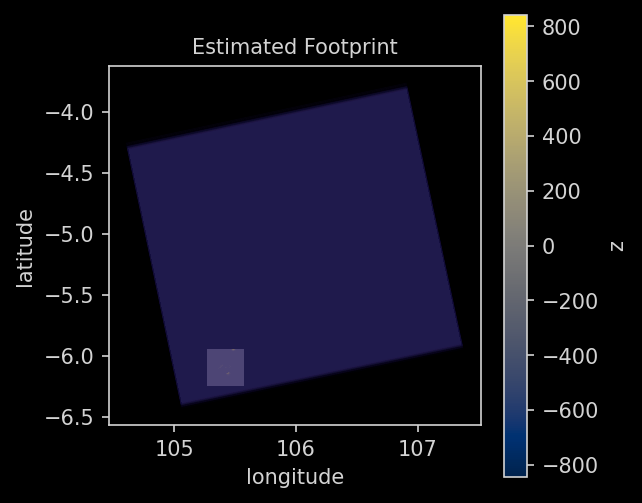

In [8]:
plt.figure(figsize=(4,4))
Tiles().download_dem(shapely.geometry.box(*BBOX).buffer(0.05), provider='GLO', filename=NISARDEM).plot.imshow(cmap='cividis')
Nisar(NISARDATADIR).plot(ax=plt.gca(), alpha=0.3)

## Coregister and geocode

`resolution=(5, 25)` is the output posting in metres (azimuth × range), matched to frequency B's
25 m range spacing. The reference date is the last scene before the September eruption.

In [9]:
nisar = Nisar(NISARDATADIR, DEM=NISARDEM)
nisar.to_dataframe()

NOTE: Loaded 18 Nisar scenes (frequencyB).


Computing Baselines      : 100%|██████████| 9/9 [00:09<00:00,  1.08s/it]

NOTE: baselines are measured from 2026-06-26.


startTime  \
sceneId polarization scene                                                        
010_175 HH           010_175/NSR_010_175_20260626T223955_HH 2026-06-26 22:39:56   
                     010_175/NSR_010_175_20260708T223954_HH 2026-07-08 22:39:55   
                     010_175/NSR_010_175_20260720T223953_HH 2026-07-20 22:39:54   
                     010_175/NSR_010_175_20260813T223952_HH 2026-08-13 22:39:53   
                     010_175/NSR_010_175_20260825T223952_HH 2026-08-25 22:39:53   
                     010_175/NSR_010_175_20260906T223952_HH 2026-09-06 22:39:53   
                     010_175/NSR_010_175_20260918T223952_HH 2026-09-18 22:39:53   
                     010_175/NSR_010_175_20260930T223952_HH 2026-09-30 22:39:53   
                     010_175/NSR_010_175_20261012T223952_HH 2026-10-12 22:39:53   
        HV           010_175/NSR_010_175_20260626T223955_HV 2026-06-26 22:39:56   
                     010_175/NSR_010_175_20260708T223954_HV 2026-07-08 22:39:55   
                     010_175/NSR_010_175_20260720T223953_HV 2026-07-20 22:39:54   
                     010_175/NSR_010_175_20260813T223952_HV 2026-08-13 22:39:53   
                     010_175/NSR_010_175_20260825T223952_HV 2026-08-25 22:39:53   
                     010_175/NSR_010_175_20260906T223952_HV 2026-09-06 22:39:53   
                     010_175/NSR_010_175_20260918T223952_HV 2026-09-18 22:39:53   
                     010_175/NSR_010_175_20260930T223952_HV 2026-09-30 22:39:53   
                     010_175/NSR_010_175_20261012T223952_HV 2026-10-12 22:39:53   

                                                                                                          path  \
sceneId polarization scene                                                                                       
010_175 HH           010_175/NSR_010_175_20260626T223955_HH  krakatau_data/010_175/NSR_010_175_20260626T223...   
                     010_175/NSR_010_175_20260708T223954_HH  krakatau_data/010_175/NSR_010_175_20260708T223...   
                     010_175/NSR_010_175_20260720T223953_HH  krakatau_data/010_175/NSR_010_175_20260720T223...   
                     010_175/NSR_010_175_20260813T223952_HH  krakatau_data/010_175/NSR_010_175_20260813T223...   
                     010_175/NSR_010_175_20260825T223952_HH  krakatau_data/010_175/NSR_010_175_20260825T223...   
                     010_175/NSR_010_175_20260906T223952_HH  krakatau_data/010_175/NSR_010_175_20260906T223...   
                     010_175/NSR_010_175_20260918T223952_HH  krakatau_data/010_175/NSR_010_175_20260918T223...   
                     010_175/NSR_010_175_20260930T223952_HH  krakatau_data/010_175/NSR_010_175_20260930T223...   
                     010_175/NSR_010_175_20261012T223952_HH  krakatau_data/010_175/NSR_010_175_20261012T223...   
        HV           010_175/NSR_010_175_20260626T223955_HV  krakatau_data/010_175/NSR_010_175_20260626T223...   
                     010_175/NSR_010_175_20260708T223954_HV  krakatau_data/010_175/NSR_010_175_20260708T223...   
                     010_175/NSR_010_175_20260720T223953_HV  krakatau_data/010_175/NSR_010_175_20260720T223...   
                     010_175/NSR_010_175_20260813T223952_HV  krakatau_data/010_175/NSR_010_175_20260813T223...   
                     010_175/NSR_010_175_20260825T223952_HV  krakatau_data/010_175/NSR_010_175_20260825T223...   
                     010_175/NSR_010_175_20260906T223952_HV  krakatau_data/010_175/NSR_010_175_20260906T223...   
                     010_175/NSR_010_175_20260918T223952_HV  krakatau_data/010_175/NSR_010_175_20260918T223...   
                     010_175/NSR_010_175_20260930T223952_HV  krakatau_data/010_175/NSR_010_175_20260930T223...   
                     010_175/NSR_010_175_20261012T223952_HV  krakatau_data/010_175/NSR_010_175_20261012T223...   

                                                             track  frame  \
sceneId polarization scene                         

In [10]:
# all in one command: load the SLC granules with the DEM and write the Zarr stack
nisar.transform(NISARZARRDIR, ref='2026-08-25', bbox=BBOX, resolution=(5, 25))

NOTE: Processing frequencyB.
NOTE: EPSG code computed automatically: 32748.


Checking Orbits          : 100%|██████████| 18/18 [00:00<00:00, 238.37it/s]


NOTE: Processing 1 scene(s), 18 dates, chunks parallel with n_jobs=2


Transforming SLC...      : 100%|██████████| 1/1 [04:14<00:00, 254.17s/it]


# Stage 2 — Visualisation: dual-pol RGB time series, animated in 2D and 3D

Everything below reads the Zarr stack and needs nothing from Stage 1.

## Load and set up Python modules

In [11]:
import sys, os
if 'google.colab' in sys.modules:
  #!{sys.executable} -m pip install -qq --progress-bar off insardev insardev-toolkit
  !{sys.executable} -m pip install -qq --progress-bar off \
    "insardev_toolkit  @ git+https://github.com/InSARdev/core@main#subdirectory=insardev_toolkit" \
    "insardev          @ git+https://github.com/InSARdev/core@main#subdirectory=insardev"
  !{sys.executable} -m pip install -qq --progress-bar off  "pyvista<0.49" xvfbwrapper jupyter_bokeh vtk panel
  from google.colab import output
  output.enable_custom_widget_manager()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [12]:
import io
import shutil
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import display, HTML, Video
%matplotlib inline

In [13]:
# import modules to be used in the notebook
from insardev import Stack
from insardev_toolkit import UI, XYZTiles
UI('dark')

In [14]:
# interactive and 3D plotting modules
import ipywidgets as widgets
import plotly.express as px
import plotly.graph_objects as go
import pyvista as pv
pv.set_plot_theme("dark")
import panel
if 'google.colab' in sys.modules:
    panel.extension('vtk', comms='ipywidgets')
else:
    panel.extension('vtk')

## Directories

In [15]:
ZARRDIR = 'krakatau_zarr'

## Dask cluster

Every step below is lazy — the calls build a task graph and `.compute()` runs it.

In [16]:
# simple Dask initialization
if 'client' in globals():
    client.shutdown()
from dask.distributed import Client
client = Client(silence_logs='CRITICAL')
client

INFO:distributed.http.proxy:To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:42921
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:39509'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:38009'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:43979 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:43979
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:47118
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:38185 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:38185
INFO:distributed.core:Starting established connection to tcp://127

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 2
Total threads: 2,Total memory: 12.67 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42921,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38185,Total threads: 1
Dashboard: http://127.0.0.1:36243/status,Memory: 6.34 GiB
Nanny: tcp://127.0.0.1:39509,


## Load the stack

In [17]:
stack = Stack().load(ZARRDIR)
stack

INFO:distributed.scheduler:Registering Worker plugin ignore_divide
Loading Dataset...       : 100%|██████████| 1/1 [00:00<00:00,  3.69it/s]


Stack['010_175']:
<xarray.Dataset> Size: 612MB
Dimensions:           (date: 9, y: 4427, x: 886)
Coordinates:
  * date              (date) datetime64[s] 72B 2026-06-26T22:39:56 ... 2026-1...
  * y                 (y) float64 35kB 9.315e+06 9.315e+06 ... 9.337e+06
  * x                 (x) float64 7kB 5.354e+05 5.354e+05 ... 5.575e+05
    spatial_ref       int64 8B 0
Data variables: (12/33)
    HH                (date, y, x) complex64 282MB dask.array<chunksize=(1, 4427, 886), meta=np.ndarray>
    burst             (date) <U30 1kB 'NSR_010_175_20260626T223955_XX' ... 'N...
    rng_samp_rate     (date) float64 72B 6e+06 6e+06 6e+06 ... 6e+06 6e+06 6e+06
    PRF               (date) float64 72B 1.52e+03 1.52e+03 ... 1.52e+03 1.52e+03
    radar_wavelength  (date) float64 72B 0.2318 0.2318 0.2318 ... 0.2318 0.2318
    near_range        (date) float64 72B 9.988e+05 9.988e+05 ... 9.987e+05
    ...                ...
    startTime         (date) <U19 684B '2026-06-26 22:39:56' ... '2026-10-12 .

In [18]:
stack.to_dataframe()

flightDirection lookdir polarization mission  \
fullBurstID startTime                                                          
010_175     2026-06-26 22:39:56               A       L        HH,HV   NISAR   
            2026-07-08 22:39:55               A       L        HH,HV   NISAR   
            2026-07-20 22:39:54               A       L        HH,HV   NISAR   
            2026-08-13 22:39:53               A       L        HH,HV   NISAR   
            2026-08-25 22:39:53               A       L        HH,HV   NISAR   
            2026-09-06 22:39:53               A       L        HH,HV   NISAR   
            2026-09-18 22:39:53               A       L        HH,HV   NISAR   
            2026-09-30 22:39:53               A       L        HH,HV   NISAR   
            2026-10-12 22:39:53               A       L        HH,HV   NISAR   

                                band frequency  pathNumber   BPR  \
fullBurstID startTime                                              
010_175     2026-06-26 22:39:56    L         B        10.0 -23.6   
            2026-07-08 22:39:55    L         B        10.0  20.0   
            2026-07-20 22:39:54    L         B        10.0  11.9   
            2026-08-13 22:39:53    L         B        10.0  10.9   
            2026-08-25 22:39:53    L         B        10.0   0.0   
            2026-09-06 22:39:53    L         B        10.0  -5.5   
            2026-09-18 22:39:53    L         B        10.0  12.6   
            2026-09-30 22:39:53    L         B        10.0 -13.9   
            2026-10-12 22:39:53    L         B        10.0  33.5   

                                                                          geometry  
fullBurstID startTime                                                               
010_175     2026-06-26 22:39:56  POLYGON ((575968.074 9317557.221, 523027.841 9...  
            2026-07-08 22:39:55  POLYGON ((575968.074 9317557.221, 523027.841 9...  
            2026-07-20 22:39:54  POLYGON ((575968.074 9317557.221, 523027.841 9...  
            2026-08-13 22:39:53  POLYGON ((575968.074 9317557.221, 523027.841 9...  
            2026-08-25 22:39:53  POLYGON ((575968.074 9317557.221, 523027.841 9...  
            2026-09-06 22:39:53  POLYGON ((575968.074 9317557.221, 523027.841 9...  
            2026-09-18 22:39:53  POLYGON ((575968.074 9317557.221, 523027.841 9...  
            2026-09-30 22:39:53  POLYGON ((575968.074 9317557.221, 523027.841 9...  
            2026-10-12 22:39:53  POLYGON ((575968.074 9317557.221, 523027.841 9...

### The scene and the view

The animation shows the Krakatau archipelago: Anak Krakatau in the centre, Rakata to the south,
Sertung to the west and Panjang to the north-east. The yellow box is a zoom on Anak Krakatau.

NOTE: 8 parallel downloads capped at 4, two per CPU.


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


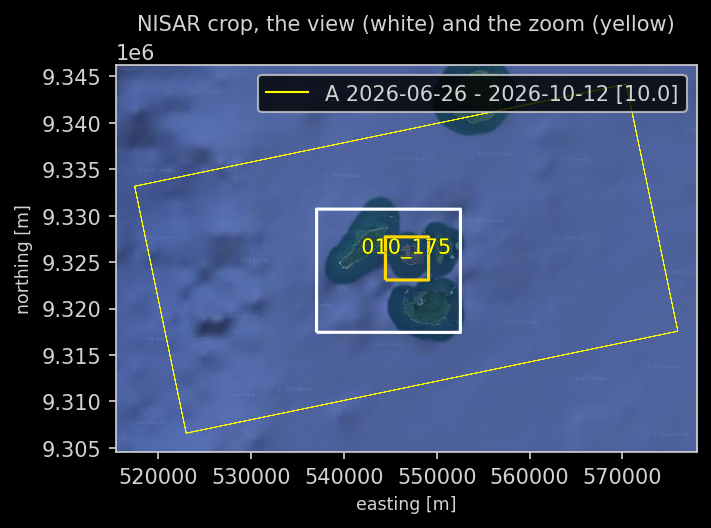

In [19]:
# the animated view and the zoom on Anak Krakatau, WGS84 (west, south, east, north)
VIEW = gpd.GeoSeries([shapely.geometry.box(105.335, -6.175, 105.475, -6.055)], crs=4326)
ISLAND = gpd.GeoSeries([shapely.geometry.box(105.402, -6.124, 105.444, -6.082)], crs=4326)

plt.figure(figsize=(5,5))
stack.plot(cmap='autumn', alpha=0.15, ax=plt.gca())
# download the basemap adding the buffer to cover the area of interest after reprojecting
gmap = XYZTiles().download_googlesatellite(stack.to_dataframe().buffer(2_000), zoom=12)
gmap.plot.imshow(ax=plt.gca(), zorder=-1, add_labels=False)
VIEW.to_crs(stack.crs).boundary.plot(ax=plt.gca(), color='white', lw=1.5)
ISLAND.to_crs(stack.crs).boundary.plot(ax=plt.gca(), color='gold', lw=1.5)
plt.gca().set_title('NISAR crop, the view (white) and the zoom (yellow)');

## Backscatter of every acquisition

`power()` is the radar intensity of each pixel. The geocoded grid is 5 m north-south and 25 m
east-west, so a Gaussian filter of `SPECKLE` metres smooths it and `downsample()` moves it to square
25 m pixels. The result is small (about 600 × 500 pixels), so it is computed into memory once and
everything below is plain NumPy.

In [20]:
# Gaussian filter wavelength and the output pixel size, metres
SPECKLE = 60
SPACING = 25
power = stack[['HH','HV']].crop(VIEW).power().gaussian(wavelength=SPECKLE).downsample(SPACING)
power = power.to_dataset().compute()[['HH', 'HV']]
# north up: the first row of the arrays is the northern edge
power = power.sortby('y', ascending=False)
# the acquisition days (the scenes are taken at 22:40 UTC)
dates = pd.DatetimeIndex(power.date.values).normalize()
power = power.assign_coords(date=dates)
power

<xarray.Dataset> Size: 24MB
Dimensions:      (date: 9, y: 531, x: 621)
Coordinates:
  * date         (date) datetime64[s] 72B 2026-06-26 2026-07-08 ... 2026-10-12
  * y            (y) float64 4kB 9.331e+06 9.331e+06 ... 9.317e+06 9.317e+06
  * x            (x) float64 5kB 5.371e+05 5.371e+05 ... 5.525e+05 5.526e+05
    spatial_ref  int64 8B 0
Data variables:
    HH           (date, y, x) float32 12MB 0.009802 0.003904 ... 0.01071 0.01204
    HV           (date, y, x) float32 12MB 0.007216 0.005034 ... 0.004534
Attributes:
    spatial_ref:  PROJCRS["WGS 84 / UTM zone 48S",BASEGEOGCRS["WGS 84",ENSEMB...

## Multi-temporal speckle filter

Radar images are grainy (speckle), and in an animation the grain flickers from frame to frame.
The multi-temporal filter of Quegan & Yu (2001) uses all nine dates: each date keeps its own local
mean brightness (in a window of `size` × `size` pixels), and the detail inside the window comes from
the average of all dates, where the speckle is about three times weaker. Changes between the dates
stay, because each date keeps its own local mean.

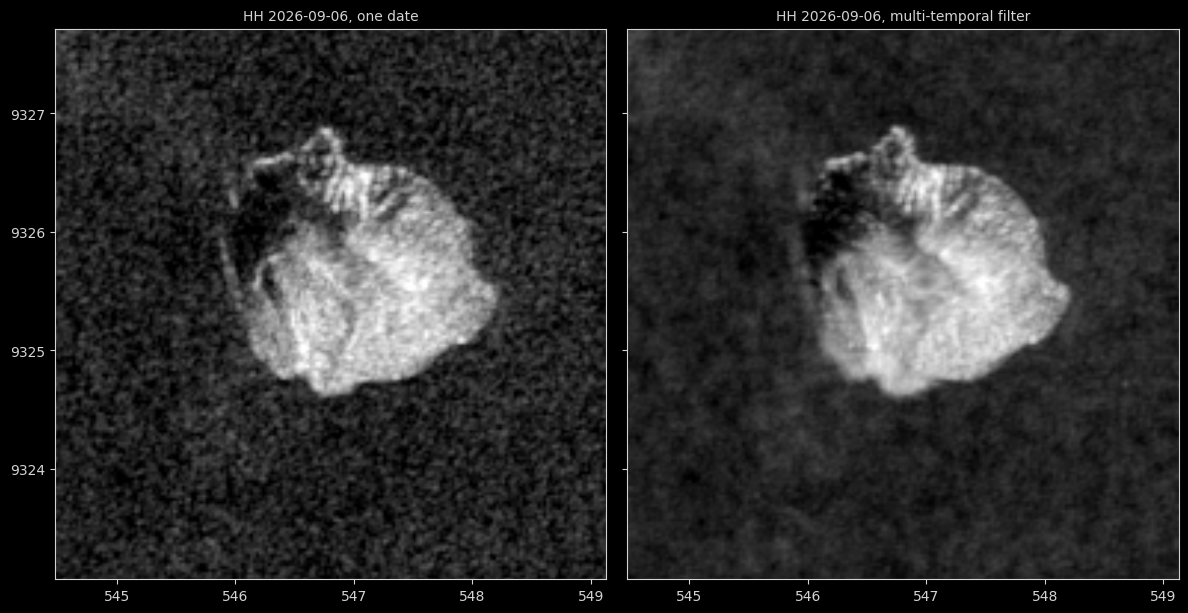

In [21]:
from scipy.ndimage import uniform_filter

def temporal_filter(da, size=5):
    """Quegan & Yu multi-temporal speckle filter of a (date, y, x) power DataArray."""
    p = da.values
    local = uniform_filter(p, size=(1, size, size))
    return da.copy(data=local * np.mean(p / local, axis=0))

# decibels, the natural scale of radar brightness
db_single = 10 * np.log10(power)
db = 10 * np.log10(power.map(temporal_filter))

# the map extent in kilometres (UTM) and the zoom box
x_km, y_km = db.x.values / 1e3, db.y.values / 1e3
extent = [x_km[0], x_km[-1], y_km[-1], y_km[0]]
zoom = ISLAND.to_crs(stack.crs).total_bounds / 1e3
def zoom_in(ax):
    ax.set_xlim(zoom[0], zoom[2])
    ax.set_ylim(zoom[1], zoom[3])

fig, axs = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True, dpi=100)
for ax, data, name in zip(axs, [db_single, db], ['one date', 'multi-temporal filter']):
    ax.imshow(data.HH.sel(date='2026-09-06'), extent=extent, cmap='gray', vmin=-22, vmax=-2, interpolation='bilinear')
    ax.set_title(f'HH 2026-09-06, {name}')
zoom_in(axs[0])
plt.tight_layout()

## Dual-pol RGB composite

* **R = HH**, co-polarised: bright for rough surfaces — rocks, fresh lava, blocks.
* **G = HV**, cross-polarised: bright for volume scattering — vegetation, rough loose deposits.
* **B = HH/HV**, their ratio: high where the surface scatters without depolarising, such as the sea.

The forested islands are yellow (bright in both HH and HV), the bare volcanic surface of Anak
Krakatau is magenta, and the sea is dark blue.

Each channel is stretched with **one fixed range for all dates**. A per-frame stretch would make the
animation flicker and would hide the real changes in brightness.

In [22]:
# one stretch range per channel, from all acquisitions
channels = {'HH': db.HH, 'HV': db.HV, 'HH/HV': db.HH - db.HV}
limits = {name: np.nanpercentile(da.values, [2, 99.5]) for name, da in channels.items()}
print({name: np.round(lim, 1) for name, lim in limits.items()})

def to_rgb(db):
    """xarray Dataset of HH and HV in dB (any leading dims) -> uint8 RGB array (..., y, x, 3)."""
    bands = [db.HH, db.HV, db.HH - db.HV]
    rgb = np.stack([np.clip((band.values.astype(np.float32) - lo) / (hi - lo), 0, 1)
                    for band, (lo, hi) in zip(bands, limits.values())], axis=-1)
    # pixels without data are black
    return (255 * np.nan_to_num(rgb)).astype(np.uint8)

rgb = to_rgb(db)
rgb.shape

{'HH': array([-21.5,  -1.9]), 'HV': array([-25. ,  -7.4]), 'HH/HV': array([1.8, 9.9])}


(9, 531, 621, 3)

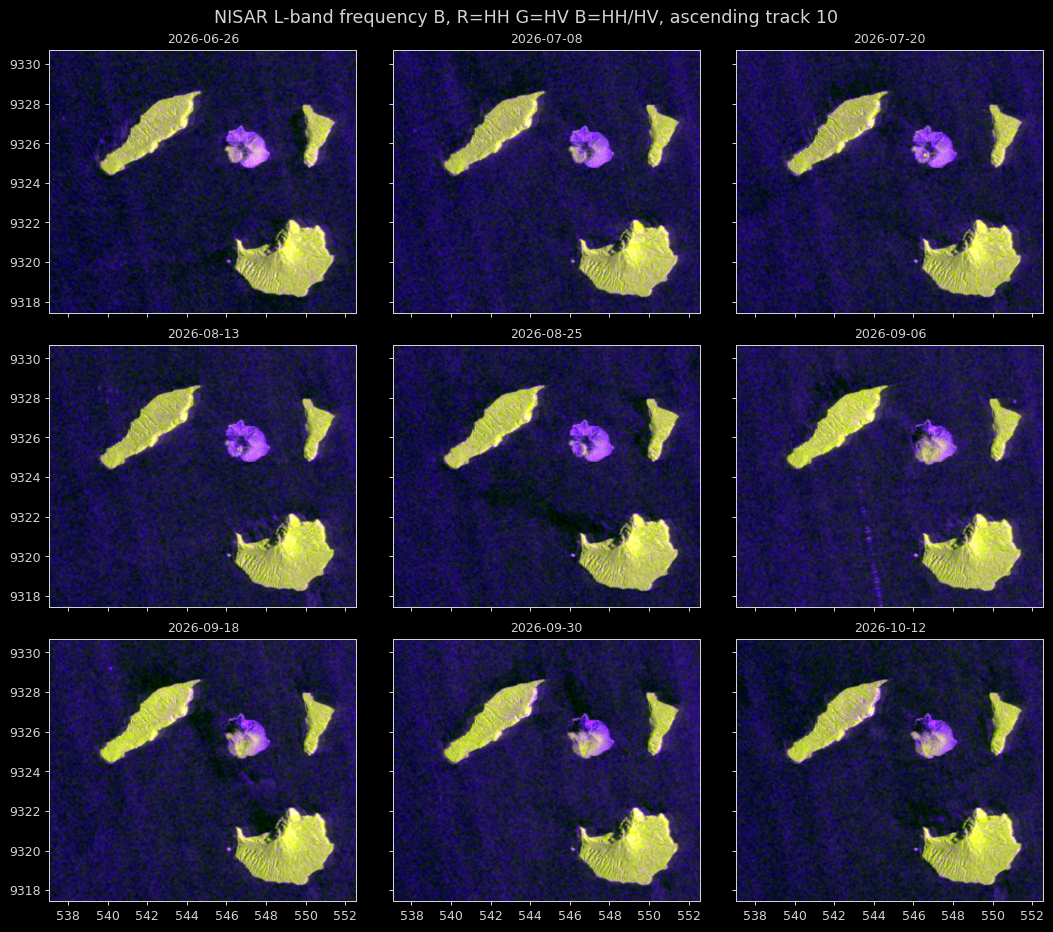

In [23]:
fig, axs = plt.subplots(3, 3, figsize=(12, 10.5), sharex=True, sharey=True, dpi=90)
for ax, image, date in zip(axs.flat, rgb, dates):
    ax.imshow(image, extent=extent, interpolation='bilinear')
    ax.set_title(date.strftime('%Y-%m-%d'))
fig.suptitle('NISAR L-band frequency B, R=HH G=HV B=HH/HV, ascending track 10', fontsize=14)
plt.tight_layout()

### What changed in the September 2026 eruption

The difference of the backscatter after and before an event, in dB, is the classic radar change
detector: red where the surface became brighter (new rough deposits, slopes turned towards the
radar), blue where it became darker (smoother surfaces, slopes turned away, land lost to the sea).

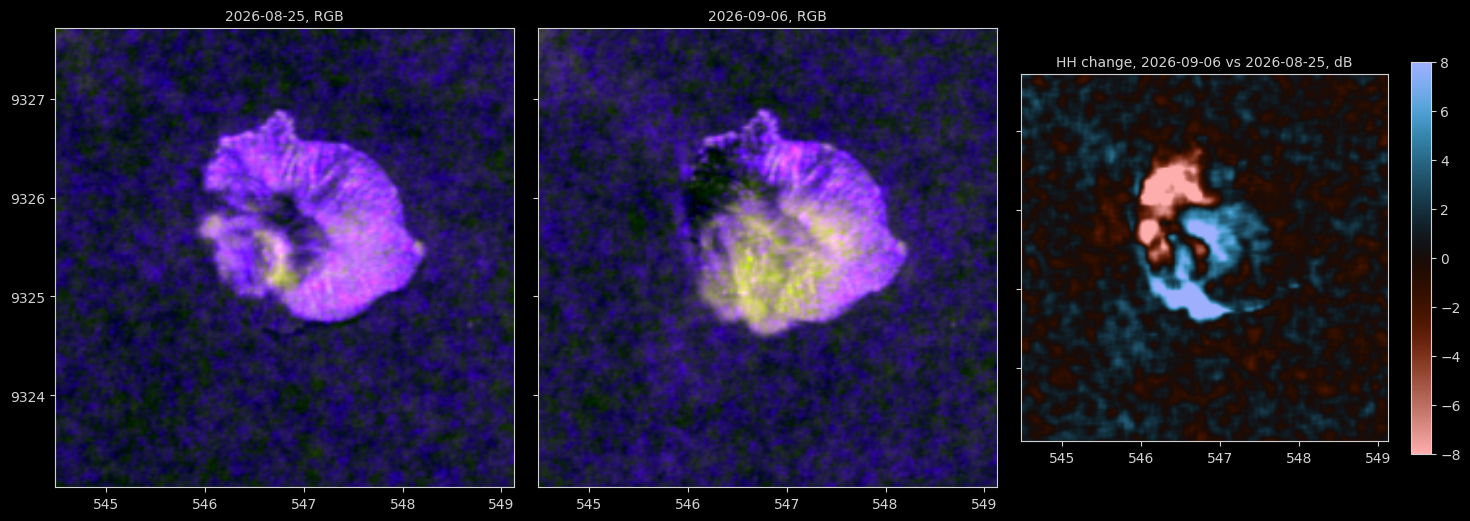

In [24]:
before, after = '2026-08-25', '2026-09-06'
change = db.HH.sel(date=after) - db.HH.sel(date=before)
fig, axs = plt.subplots(1, 3, figsize=(15, 5.2), sharex=True, sharey=True, dpi=100)
for ax, date in zip(axs[:2], [before, after]):
    ax.imshow(rgb[dates.get_loc(pd.Timestamp(date))], extent=extent, interpolation='bilinear')
    ax.set_title(f'{date}, RGB')
im = axs[2].imshow(change, extent=extent, cmap='berlin_r', vmin=-8, vmax=8, interpolation='bilinear')
axs[2].set_title(f'HH change, {after} vs {before}, dB')
plt.colorbar(im, ax=axs[2], shrink=0.8)
zoom_in(axs[0])
plt.tight_layout()

## Smooth frames between the acquisitions

The acquisitions are 12 days apart (24 days from 20 July to 13 August, where one is missing). A
linear blend between them shows visible "kinks" in brightness at every acquisition, and a cubic
spline overshoots, creating brightness that was never measured. **PCHIP**, the piecewise cubic
Hermite interpolation, is smooth and never overshoots: every daily frame lies between its two
neighbouring acquisitions, and every acquisition is reproduced exactly. It interpolates the dB
values of each pixel in time; it does not move features, because the radar shows changes of the
surface, not motion.

In [25]:
# one frame per day, in decibels, then to RGB
days = pd.date_range(dates[0], dates[-1], freq='1D', unit=dates.unit)
db_daily = db.interp(date=days, method='pchip')
rgb_daily = to_rgb(db_daily)
# the acquisitions are reproduced exactly
assert np.array_equal(rgb_daily[days.get_indexer(dates)], rgb)
is_acquisition = days.isin(dates)
def frame_title(i):
    return f'InSAR.dev: Anak Krakatau Eruption {days[i]:%Y-%m-%d} (interpolated)'
rgb_daily.shape

(109, 531, 621, 3)

## matplotlib + ffmpeg: a video

`FuncAnimation` draws each frame: the archipelago, the zoom on Anak Krakatau, the date, and a
timeline (white: the acquisitions, red: the 4–8 September eruption). ffmpeg encodes them to an
H.264 MP4 file that plays in any browser, can be posted on social media, and stays in the saved
notebook. Without ffmpeg, `to_jshtml()` makes a JavaScript player of the same frames.

In [26]:
# frames per second of the videos: one day per frame
FPS = 12

fig = plt.figure(figsize=(11, 6))
ax_map = fig.add_axes([0.07, 0.16, 0.43, 0.74])
ax_zoom = fig.add_axes([0.54, 0.16, 0.44, 0.74])
ax_time = fig.add_axes([0.07, 0.05, 0.91, 0.04])
images = [ax.imshow(rgb_daily[0], extent=extent, interpolation='bilinear') for ax in (ax_map, ax_zoom)]
zoom_in(ax_zoom)
ax_map.add_patch(plt.Rectangle((zoom[0], zoom[1]), zoom[2] - zoom[0], zoom[3] - zoom[1], fill=False, ec='gold', lw=1.5))
ax_map.set_ylabel('Northing, km')
for ax in (ax_map, ax_zoom):
    ax.set_xlabel('Easting, km')
title = fig.suptitle('', fontsize=15)
# the timeline: acquisitions and the September eruption
ax_time.set_xlim(days[0], days[-1])
ax_time.set_yticks([])
ax_time.axvspan(pd.Timestamp('2026-09-04'), pd.Timestamp('2026-09-08'), color='orangered', alpha=0.7)
for date in dates:
    ax_time.axvline(date, color='white', lw=1)
cursor = ax_time.axvline(days[0], color='gold', lw=3)

def update(i):
    for image in images:
        image.set_data(rgb_daily[i])
    title.set_text(frame_title(i))
    cursor.set_xdata([days[i], days[i]])
    return *images, title, cursor

anim = animation.FuncAnimation(fig, update, frames=len(days), interval=1000 / FPS)
plt.close(fig)

if animation.writers.is_available('ffmpeg'):
    anim.save('krakatau.mp4', writer=animation.FFMpegWriter(fps=FPS, codec='libx264',
                                                               extra_args=['-pix_fmt', 'yuv420p', '-crf', '22']))
    display(Video('krakatau.mp4', embed=True, html_attributes='controls loop autoplay muted'))
else:
    plt.rcParams['animation.embed_limit'] = 100
    display(HTML(anim.to_jshtml()))

## Export from Google Colab

In [27]:
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download('krakatau.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>